# Does yesterday's move undo itself? — Stage 1: an honest replication in FX and commodities

**Project:** Mean reversion across FX and commodities · **Stage 1 of 4** · Heritage Edge

### The question in one sentence
A YouTube notebook found that Bitcoin Cash tends to *bounce back* the day after it moves. **Does the same thing happen in EURUSD, USDJPY, gold and oil — and does it still make money after paying for each trade?**

### The idea, explained simply
Imagine a rubber band. Pull it one way and it snaps back. *Mean reversion* is the bet that prices behave like that rubber band:

* Price went **down** yesterday → bet it goes **up** today (**buy**, also called going *long*).
* Price went **up** yesterday → bet it goes **down** today (**sell**, also called going *short*).

### What this notebook fixes compared with the original
| Original crypto notebook | This notebook |
|---|---|
| One coin, picked because it worked | Four markets chosen *before* looking at results |
| Added daily returns together (no compounding) | Grows the account properly, day after day |
| Charged fees every day, as a maker | Pays the **spread** only on days we actually change position |
| `12 * r` (not a real annual figure) | Proper annual return (CAGR) |
| Sharpe with 365 days | Sharpe with 252 trading days |
| No check for luck | t-stat: is the edge bigger than the noise? |
| Days with zero move counted as "down" | Zero-move days count as "no signal" |

> **A "no edge" result is a good result.** The point of Stage 1 is to see clearly. If the effect isn't there in FX, that's the finding — and it tells us why Stages 2–4 exist.

## 1. Setup
`yfinance` downloads free daily prices from Yahoo Finance. In Google Colab, run the cell below once.

In [2]:
# Run once (in Colab or a fresh environment)
%pip install -q yfinance pandas numpy matplotlib jinja2

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)

Matplotlib is building the font cache; this may take a moment.


## 2. Settings — the markets and what each trade costs

### What does a trade *cost* in FX and commodities?
In crypto you pay an exchange **fee**. In FX and commodities you mostly pay the **spread**: the gap between the price you can buy at and the price you can sell at.

> **Everyday example:** a bureau de change buys your pounds at 1.10 euros but sells pounds at 1.20. That 0.10 gap is the spread. Every time you swap, you lose a bit of it.

We write costs in **basis points (bps)**. One basis point = 0.01% = 1/10,000. So 1 bp on a £10,000 trade costs £1.

`COST_BPS` is the cost **each time we trade one unit in one direction** (roughly half the spread, plus a little slippage). The numbers below are deliberately on the realistic side for a small trader, not a bank.

> **Slippage** = the price moving against you between deciding to trade and actually trading.

In [4]:
MARKETS = {
    # name      : Yahoo ticker
    "EURUSD"    : "EURUSD=X",   # euro vs US dollar
    "USDJPY"    : "JPY=X",      # US dollar vs Japanese yen
    "Gold"      : "GC=F",       # gold futures (front month)
    "WTI oil"   : "CL=F",       # US crude oil futures (front month)
}

COST_BPS = {        # one-way cost per unit traded, in basis points
    "EURUSD"  : 0.5,
    "USDJPY"  : 0.7,
    "Gold"    : 1.5,
    "WTI oil" : 2.5,
}

START, END = "2012-01-01", "2026-10-01"
TRADING_DAYS = 252      # FX/commodities trade ~252 days a year, not 365 like crypto

## 3. Download the prices and check them

We only need the **close** price for each day. Before using any data, we check it — the original notebook had rows with zero volume, which is a warning sign.

Things we check:
* **Missing days** — dropped.
* **Prices at or below zero** — oil famously closed at **−$37** in April 2020. You can't take the log of a negative number, so those days are removed and flagged.
* **Huge jumps** (moves bigger than 10% in a day) — printed so you can eyeball whether they're real events or data errors.

> **Heads-up about futures (gold, oil):** Yahoo's `GC=F` and `CL=F` stitch together contracts that expire each month. When one contract is swapped for the next (*the roll*), the price can jump even though nothing happened in the market. Stage 4 will fix this properly; for now just be aware the oil and gold results are slightly noisier.

In [5]:
def download_closes(markets, start, end):
    closes = {}
    for name, ticker in markets.items():
        data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=False)
        if data.empty:
            raise ValueError(f"No data came back for {name} ({ticker}). Check the ticker or your internet.")
        close = data["Close"]
        if isinstance(close, pd.DataFrame):      # newer yfinance returns one column per ticker
            close = close.iloc[:, 0]
        closes[name] = close.rename(name)
    return closes

raw = download_closes(MARKETS, START, END)

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

In [6]:
def clean(close, name):
    s = close.dropna()
    s = s[~s.index.duplicated(keep="last")].sort_index()
    bad = s[s <= 0]
    if len(bad):
        print(f"{name}: removed {len(bad)} day(s) with price <= 0 -> {list(bad.index.date)}")
    s = s[s > 0]
    big = np.log(s).diff().abs()
    big = big[big > 0.10]
    if len(big):
        print(f"{name}: {len(big)} day(s) moved more than 10% -> {list(big.index.date)}")
    return s

prices = {name: clean(s, name) for name, s in raw.items()}

summary = pd.DataFrame({
    "first day": {k: v.index.min().date() for k, v in prices.items()},
    "last day":  {k: v.index.max().date() for k, v in prices.items()},
    "days":      {k: len(v) for k, v in prices.items()},
})
summary

Gold: 1 day(s) moved more than 10% -> [datetime.date(2026, 1, 30)]
WTI oil: removed 1 day(s) with price <= 0 -> [datetime.date(2020, 4, 20)]
WTI oil: 28 day(s) moved more than 10% -> [datetime.date(2014, 11, 28), datetime.date(2016, 1, 21), datetime.date(2016, 2, 12), datetime.date(2019, 9, 16), datetime.date(2020, 3, 6), datetime.date(2020, 3, 9), datetime.date(2020, 3, 16), datetime.date(2020, 3, 18), datetime.date(2020, 3, 19), datetime.date(2020, 3, 20), datetime.date(2020, 4, 2), datetime.date(2020, 4, 3), datetime.date(2020, 4, 14), datetime.date(2020, 4, 21), datetime.date(2020, 4, 22), datetime.date(2020, 4, 23), datetime.date(2020, 4, 27), datetime.date(2020, 4, 29), datetime.date(2020, 4, 30), datetime.date(2020, 5, 5), datetime.date(2021, 11, 26), datetime.date(2022, 3, 9), datetime.date(2026, 3, 6), datetime.date(2026, 3, 10), datetime.date(2026, 3, 23), datetime.date(2026, 4, 2), datetime.date(2026, 4, 8), datetime.date(2026, 4, 17)]


,first day,last day,days
EURUSD,2012-01-02,2026-09-30,3838
USDJPY,2012-01-02,2026-09-30,3839
Gold,2012-01-03,2026-09-30,3707
WTI oil,2012-01-03,2026-09-30,3706


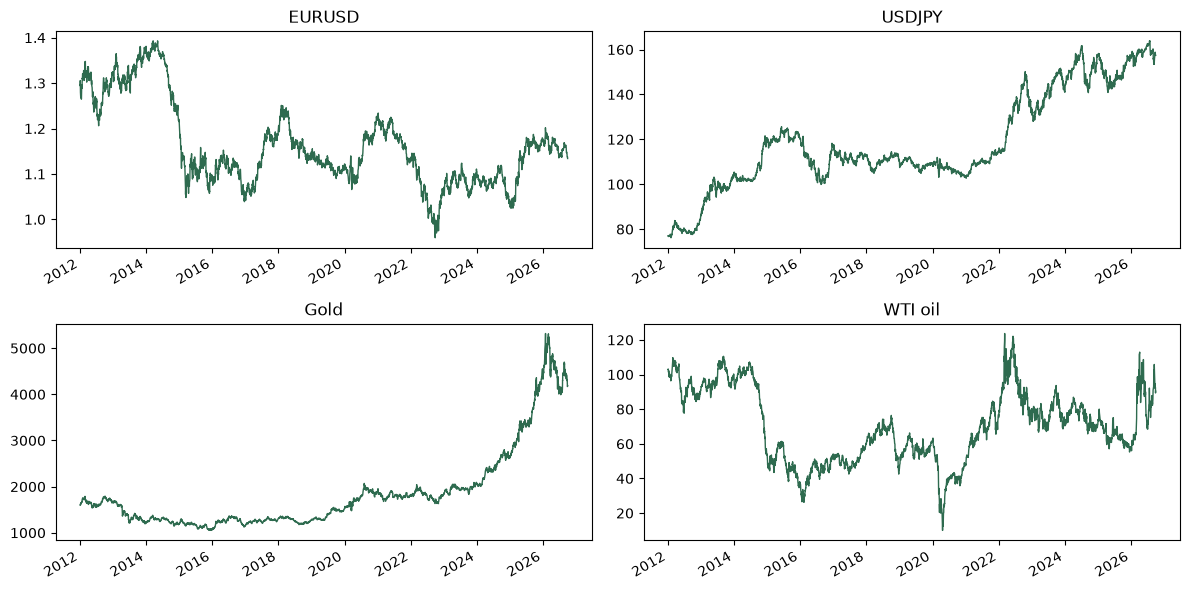

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (name, s) in zip(axes.flat, prices.items()):
    s.plot(ax=ax, color="#2E6B4F", lw=1)
    ax.set_title(name); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 4. Daily returns, and yesterday's direction

A **return** is how much the price moved, as a fraction. We use **log returns** to *measure* moves because they add up neatly over time:

$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right)$$

where $P_t$ is today's closing price and $P_{t-1}$ is yesterday's.

**Direction** of yesterday's move:
* $+1$ if yesterday was up
* $-1$ if yesterday was down
* $0$ if the price didn't move at all (the original code wrongly counted these as "down")

`np.sign` does exactly this.

In [8]:
def make_frame(close):
    df = pd.DataFrame({"close": close})
    df["log_ret"]   = np.log(df["close"]).diff()          # today's move (for measuring)
    df["simple_ret"] = df["close"].pct_change()           # today's move (for money: +1% = x1.01)
    df["prev_dir"]  = np.sign(df["log_ret"].shift(1))     # yesterday's direction: +1, -1 or 0
    return df.dropna()

frames = {name: make_frame(s) for name, s in prices.items()}
frames["EURUSD"].head()

,close,log_ret,simple_ret,prev_dir
Date,,,,
2012-01-04,1.3056,0.0089,0.0089,-1.0000
2012-01-05,1.2931,-0.0096,-0.0095,1.0000
2012-01-06,1.2796,-0.0105,-0.0105,-1.0000
2012-01-09,1.2680,-0.0091,-0.0090,-1.0000
2012-01-10,1.2776,0.0075,0.0075,-1.0000


## 5. Step 1 — Is the pattern even there?

Same check as the original: group the days by **what happened yesterday**, then look at the **average move today**.

If mean reversion is real:
* after a **down** day (−1), today's average move should be **positive**
* after an **up** day (+1), today's average move should be **negative**

### Is it real, or just luck? The t-stat
A tiny average could happen by chance. The **t-stat** asks: *how many times bigger is the average than the random wobble around it?*

$$t = \frac{\bar{r}}{s / \sqrt{n}}$$

* $\bar r$ = average return, $s$ = how much returns wobble (standard deviation), $n$ = number of days.
* **Rule of thumb:** $|t| < 2$ → could easily be luck. $|t| > 2$ → probably real. Professionals often want $|t| > 3$, because people test lots of ideas and some will look good by accident.

We also show the **lag-1 autocorrelation**: a number between −1 and +1 that says how much today's move "copies" yesterday's. **Negative = rubber band (mean reversion). Positive = momentum. Near zero = no link.**

In [9]:
def t_stat(x):
    x = pd.Series(x).dropna()
    return x.mean() / (x.std() / np.sqrt(len(x))) if len(x) > 1 else np.nan

rows = []
for name, df in frames.items():
    for d, label in [(-1, "after a DOWN day"), (1, "after an UP day")]:
        today = df.loc[df["prev_dir"] == d, "log_ret"]
        rows.append({
            "market": name, "yesterday": label, "days": len(today),
            "avg move today (bps)": today.mean() * 1e4,
            "t-stat": t_stat(today),
        })
pattern = pd.DataFrame(rows).set_index(["market", "yesterday"])

autocorr = pd.Series({n: df["log_ret"].autocorr(lag=1) for n, df in frames.items()},
                     name="lag-1 autocorrelation")
display(pattern)
display(autocorr.to_frame())

days  avg move today (bps)  t-stat
market  yesterday                                           
EURUSD  after a DOWN day  1944                0.7871  0.7084
        after an UP day   1873               -1.4322 -1.2646
USDJPY  after a DOWN day  1788                2.7395  1.9721
        after an UP day   2044                1.0419  0.8351
Gold    after a DOWN day  1770                6.7951  2.7039
        after an UP day   1918               -0.5666 -0.2286
WTI oil after a DOWN day  1759                3.7758  0.4946
        after an UP day   1933               -3.9018 -0.6761

,lag-1 autocorrelation
EURUSD,-0.0305
USDJPY,-0.0179
Gold,-0.0386
WTI oil,-0.0440


**How to read this:** for the rubber band to exist, the "after a DOWN day" rows need a *positive* average with a t-stat above about 2, and the "after an UP day" rows a *negative* average with a t-stat below about −2. Write down what you see before moving on — that's your honest first finding.

## 6. Step 2 — Turn the pattern into a strategy, with real costs

### The rule
$$\text{position}_t = -\,\text{sign}(r_{t-1})$$

So we hold **+1** (long) after a down day, **−1** (short) after an up day, and **0** (nothing) after a flat day.

### When do we actually pay?
We only pay the spread when the **position changes**. The amount we trade each day is called **turnover**:

$$\text{turnover}_t = \left|\,\text{position}_t - \text{position}_{t-1}\right|$$

| Yesterday's position | Today's position | Turnover | What happened |
|---|---|---|---|
| +1 | +1 | 0 | held — no cost |
| +1 | −1 | 2 | sold to close *and* sold again to go short — pay twice |
| 0 | +1 | 1 | opened a trade — pay once |

### Growing the account properly (compounding)
Each day the account is multiplied by:

$$\left(1 + \text{position}_t \times R_t - \text{turnover}_t \times \text{cost}\right)$$

where $R_t$ is today's **simple** return (a 1% rise means ×1.01). Multiplying day after day is **compounding** — what really happens to money. The original notebook *added* returns instead, which flatters long backtests.

In [10]:
def run_strategy(df, cost_bps, delay=0):
    # delay=0: trade at the close we just saw.  delay=1: trade one day later (stricter test).
    out = df.copy()
    out["position"] = -out["prev_dir"].shift(delay).fillna(0)
    out["turnover"] = out["position"].diff().abs().fillna(out["position"].abs())
    out["cost"]     = out["turnover"] * cost_bps / 1e4
    out["gross_ret"] = out["position"] * out["simple_ret"]
    out["net_ret"]   = out["gross_ret"] - out["cost"]
    out["gross_equity"] = (1 + out["gross_ret"]).cumprod()
    out["net_equity"]   = (1 + out["net_ret"]).cumprod()
    return out

results = {name: run_strategy(df, COST_BPS[name]) for name, df in frames.items()}
results["EURUSD"][["close", "prev_dir", "position", "turnover", "cost", "net_ret", "net_equity"]].head(8)

,close,prev_dir,position,turnover,cost,net_ret,net_equity
Date,,,,,,,
2012-01-04,1.3056,-1.0000,1.0000,1.0000,0.0001,0.0088,1.0088
2012-01-05,1.2931,1.0000,-1.0000,2.0000,0.0001,0.0094,1.0184
2012-01-06,1.2796,-1.0000,1.0000,2.0000,0.0001,-0.0106,1.0076
2012-01-09,1.2680,-1.0000,1.0000,0.0000,0.0000,-0.0090,0.9985
2012-01-10,1.2776,-1.0000,1.0000,0.0000,0.0000,0.0075,1.0060
2012-01-11,1.2752,1.0000,-1.0000,2.0000,0.0001,0.0018,1.0078
2012-01-12,1.2724,-1.0000,1.0000,2.0000,0.0001,-0.0023,1.0055
2012-01-13,1.2821,-1.0000,1.0000,0.0000,0.0000,0.0076,1.0131


## 7. The scorecard

| Measure | What it means in plain words |
|---|---|
| **CAGR** | The steady yearly growth rate that would turn your starting money into your ending money |
| **Volatility** | How bumpy the ride is, per year |
| **Sharpe** | Return per unit of bumpiness. Above 1 is good; above 2 is rare and suspicious |
| **Max drawdown** | The worst fall from a high point to a low point. "How much would I have lost at the worst moment?" |
| **Win rate** | Share of days the trade made money |
| **t-stat** | Is the average daily profit bigger than the noise? (see Step 1) |
| **Trades / year** | How busy the strategy is — busier means more costs |
| **Cost drag** | How much return per year the spread eats |

$$\text{Sharpe} = \frac{\text{average daily return}}{\text{daily standard deviation}} \times \sqrt{252}$$

$$\text{CAGR} = \left(\frac{\text{ending equity}}{\text{starting equity}}\right)^{1/\text{years}} - 1$$

In [11]:
def scorecard(ret, turnover=None, cost=None):
    ret = ret.dropna()
    years = len(ret) / TRADING_DAYS
    equity = (1 + ret).cumprod()
    drawdown = equity / equity.cummax() - 1
    card = {
        "CAGR":          equity.iloc[-1] ** (1 / years) - 1,
        "Volatility":    ret.std() * np.sqrt(TRADING_DAYS),
        "Sharpe":        ret.mean() / ret.std() * np.sqrt(TRADING_DAYS),
        "Max drawdown":  drawdown.min(),
        "Win rate":      (ret[ret != 0] > 0).mean(),
        "t-stat":        t_stat(ret),
    }
    if turnover is not None:
        card["Trades / year"] = (turnover > 0).sum() / years
    if cost is not None:
        card["Cost drag / year"] = cost.sum() / years
    return card

cards = {}
for name, r in results.items():
    cards[(name, "before costs")] = scorecard(r["gross_ret"])
    cards[(name, "after costs")]  = scorecard(r["net_ret"], r["turnover"], r["cost"])

table = pd.DataFrame(cards).T
pct_cols = ["CAGR", "Volatility", "Max drawdown", "Win rate", "Cost drag / year"]
table.style.format({**{c: "{:.1%}" for c in pct_cols},
                    "Sharpe": "{:.2f}", "t-stat": "{:.2f}", "Trades / year": "{:.0f}"}, na_rep="—")

## 8. Equity curves — before and after costs

Each line starts at **1.0** (think £1). Where it ends is what £1 would have become.
* **Green dashed** = before costs (the dream).
* **Dark solid** = after costs (reality).

The gap between the two lines *is* the spread you paid.

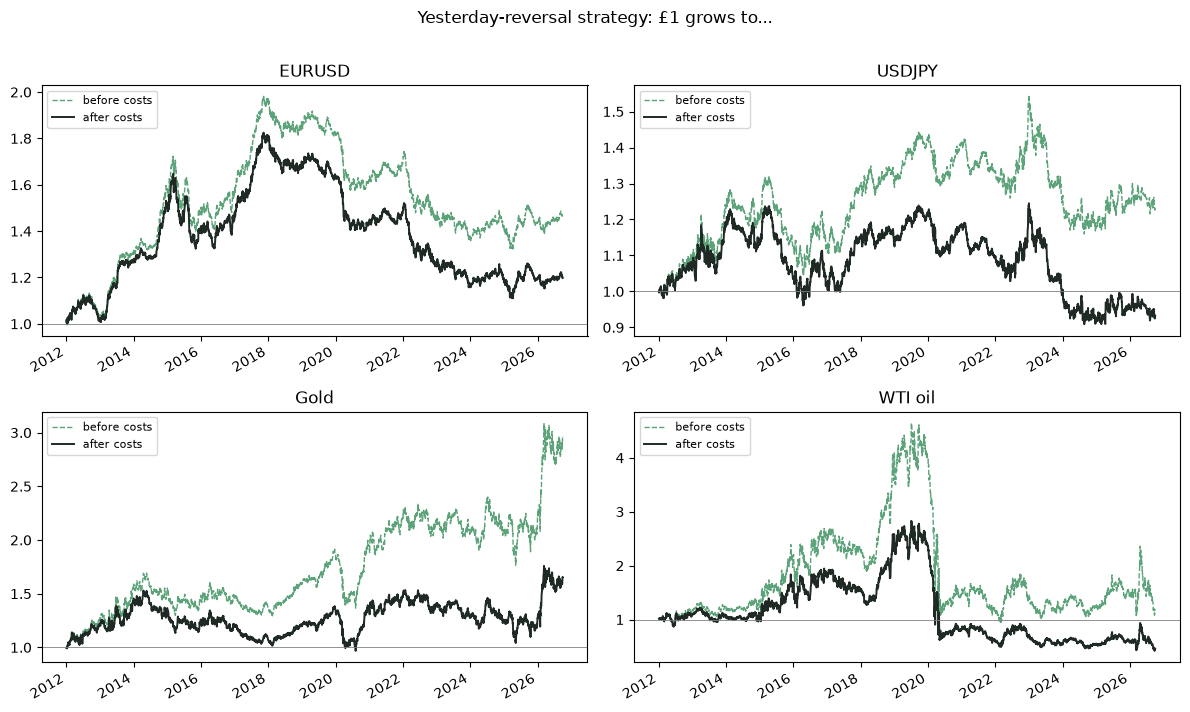

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=False)
for ax, (name, r) in zip(axes.flat, results.items()):
    r["gross_equity"].plot(ax=ax, color="#5DA37A", ls="--", lw=1, label="before costs")
    r["net_equity"].plot(ax=ax, color="#1F2A24", lw=1.4, label="after costs")
    ax.axhline(1, color="grey", lw=0.6)
    ax.set_title(name); ax.set_xlabel(""); ax.legend(loc="upper left", fontsize=8)
plt.suptitle("Yesterday-reversal strategy: £1 grows to...", y=1.01)
plt.tight_layout(); plt.show()

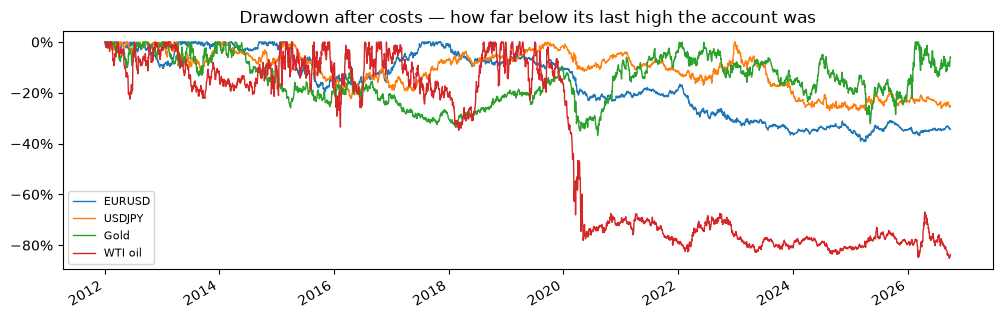

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for name, r in results.items():
    eq = r["net_equity"]
    (eq / eq.cummax() - 1).plot(ax=ax, lw=1, label=name)
ax.set_title("Drawdown after costs — how far below its last high the account was")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(fontsize=8); ax.set_xlabel(""); plt.show()

## 9. What if trading costs more than we think?

Our cost guesses could be wrong. A robust strategy should survive if costs are **higher** than expected. Below we re-run everything with costs at 0×, 0.5×, 1×, 2× and 3× our estimate.

> **How to read it:** if a line drops below zero as soon as costs go up a bit, the "edge" is too thin to trade. This chart is one of the most useful things to show a trading desk — it shows you understand that costs, not the signal, usually decide whether a strategy works.

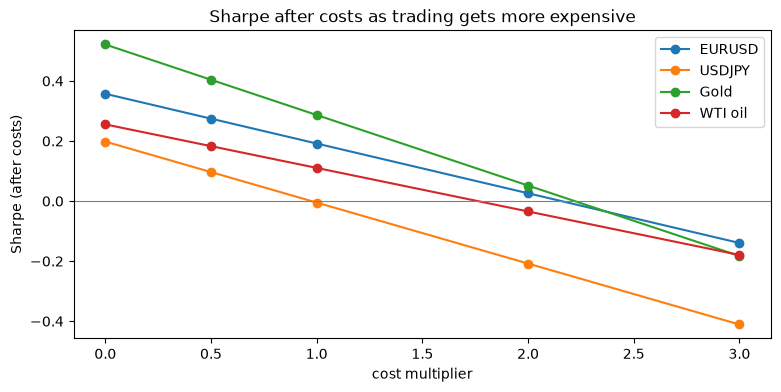

,EURUSD,USDJPY,Gold,WTI oil
cost multiplier,,,,
0.0000,0.3600,0.2000,0.5200,0.2600
0.5000,0.2700,0.1000,0.4000,0.1800
1.0000,0.1900,-0.0000,0.2900,0.1100
2.0000,0.0300,-0.2100,0.0500,-0.0300
3.0000,-0.1400,-0.4100,-0.1800,-0.1800


In [14]:
multipliers = [0, 0.5, 1, 2, 3]
sens = pd.DataFrame({
    name: [scorecard(run_strategy(frames[name], COST_BPS[name] * m)["net_ret"])["Sharpe"] for m in multipliers]
    for name in frames
}, index=multipliers)
sens.index.name = "cost multiplier"

ax = sens.plot(marker="o", figsize=(9, 4))
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Sharpe after costs as trading gets more expensive")
ax.set_ylabel("Sharpe (after costs)"); plt.show()
sens.round(2)

## 10. Does it hold up over time?

The original notebook split the data into the first 75% and last 25%. We do that too, **and** look year by year — a strategy that only worked in one lucky year isn't a strategy.

> Nothing here is "fitted" (there are no settings we tuned), so this is really a check that the pattern doesn't come and go. Proper training-vs-testing (*walk-forward*) arrives in Stage 4, when we do have settings to tune.

In [15]:
split_rows = {}
for name, r in results.items():
    cut = int(len(r) * 0.75)
    split_rows[(name, "first 75%")] = scorecard(r["net_ret"].iloc[:cut])
    split_rows[(name, "last 25%")]  = scorecard(r["net_ret"].iloc[cut:])
pd.DataFrame(split_rows).T[["CAGR", "Sharpe", "Max drawdown", "t-stat"]].style.format(
    {"CAGR": "{:.1%}", "Sharpe": "{:.2f}", "Max drawdown": "{:.1%}", "t-stat": "{:.2f}"})

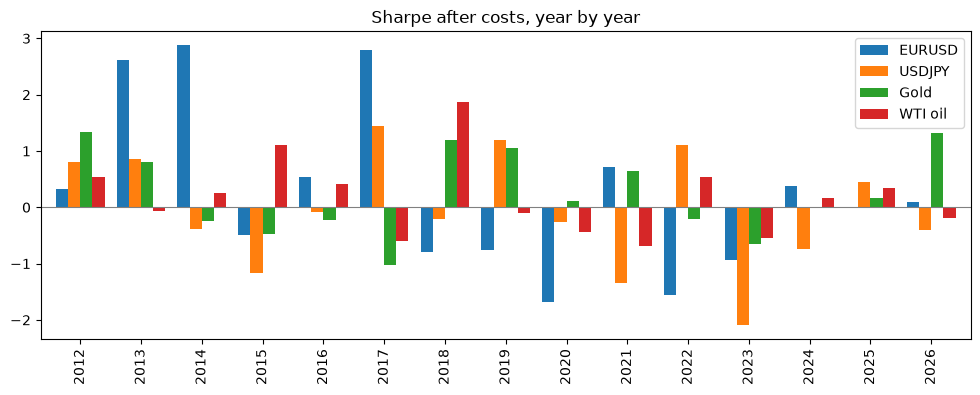

In [16]:
yearly = pd.DataFrame({
    name: r["net_ret"].groupby(r.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(TRADING_DAYS))
    for name, r in results.items()
})
ax = yearly.plot(kind="bar", figsize=(12, 4), width=0.8)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Sharpe after costs, year by year"); ax.set_xlabel("")
plt.show()

## 11. A stricter test — what if we're one day late?

So far we assumed we see yesterday's close **and** trade at that exact same price. In real life that's hard: by the time you've seen the close, the price has moved on.

Here we wait **one extra day** before acting. If the edge disappears completely, it was living in the very last moments of each day — the hardest part to actually capture.

In [17]:
delay_cmp = pd.DataFrame({
    name: {
        "Sharpe (trade at the close)":  scorecard(results[name]["net_ret"])["Sharpe"],
        "Sharpe (one day late)":        scorecard(run_strategy(frames[name], COST_BPS[name], delay=1)["net_ret"])["Sharpe"],
    } for name in frames
}).T
delay_cmp.round(2)

,Sharpe (trade at the close),Sharpe (one day late)
EURUSD,0.1900,-0.1200
USDJPY,-0.0000,-0.2900
Gold,0.2900,-0.3600
WTI oil,0.1100,0.0100


## 12. Findings

* **Is the rubber band there?** Mostly no. EURUSD and WTI point the right way but are too weak to rule out luck (|t| < 1.3). USDJPY shows no reversal, just a steady upward drift. Gold is the one exception, but only on one side: it rose 6.8 bps on average after down days (t = 2.7), while up days weren't followed by any fall. That looks like buy-the-dip behaviour in a long bull market rather than true mean reversion.

* **Does it survive costs?** No. The strategy flips position about 130 times a year, so costs take half or more of the Sharpe. Gold holds up best (0.52 before costs to 0.29 after, t-stat 2.0 to 1.1). EURUSD goes from 0.36 to 0.19 and USDJPY to zero. WTI loses 5.1% a year with an 85% drawdown despite a slightly positive Sharpe, because its 45% volatility drags compounded growth below zero.

* **How sensitive is it?** Very. USDJPY breaks even at our cost estimate, WTI at about 1.8x it, and EURUSD and gold at about 2.2x — but their Sharpes are already near zero by 2x. Even with free trading, the best Sharpe was 0.52.

* **Is it stable?** No. From 2012–2022 to 2023 onwards, EURUSD's Sharpe went from 0.30 to −0.17 and USDJPY's from 0.22 to −0.64. Gold stayed positive in both halves but without statistical significance. Each market was profitable in only 6–8 of 15 years, about what a coin toss would give.

* **Does being one day late kill it?** Yes, in every market. Gold flips from 0.29 to −0.36, EURUSD from 0.19 to −0.12. Any edge exists only at the exact close, which is hard to capture in practice.

**Verdict:** The one-day reversal that looked strong in Bitcoin Cash does not carry over to deep, heavily traded FX and commodity markets. After realistic costs, a one-day delay and a check over time, there is no tradeable edge.
### Why FX majors probably *don't* show much
Big currency pairs are the most traded markets in the world. If yesterday's move reliably reversed, thousands of banks and funds would already be trading it — and their trading would wipe the pattern out. A weak or missing edge here is **expected**, and it's exactly why the next stages look somewhere smarter.

## What comes next
* **Stage 2 — only trade the big moves.** Instead of reacting to every wiggle, trade only when yesterday's move was unusually large for that market (a *z-score*), and size each trade so every day carries similar risk.
* **Stage 3 — trade the gap between cousins.** Gold vs silver, Brent vs WTI, AUDUSD vs NZDUSD: when the gap between two related prices stretches unusually wide, bet it closes.
* **Stage 4 — the honesty layer.** Proper futures roll handling, overnight swap costs, and walk-forward testing.